In [9]:
from preamble import *

%config InlineBackend.figure_format = 'retina'


In [10]:
import sys, pandas

print("ABC version:", abc.__version__)
print("Python version:", sys.version)
print("Numpy version:", np.__version__)
print("PyMC3 version:", pm.__version__)
print("Arviz version:", arviz.__version__)
print("Pandas version:", pandas.__version__)

tic()

ABC version: 0.2.1
Python version: 3.8.20 (default, Oct  3 2024, 15:24:27) 
[GCC 11.2.0]
Numpy version: 1.22.3
PyMC3 version: 3.11.4
Arviz version: 0.12.1
Pandas version: 2.0.3


In [11]:
numIters = 10
popSize = 1000
smcArgs = {"verbose": True, "numProcs": 40}

In [12]:
rg = default_rng(123)

sample_sizes = [50, 250]
T = sample_sizes[-1]

# Frequency-Loss Model
sigma = 0.2
w1 = 15
w2 = 5
m1 = 10
m2 = 40
θ_True = sigma, w1, w2, m1, m2

freq = "bivariate poisson"
sev = "exponential"

# Aggregation process
psi = abc.Psi("sum")

claimsData = abc.simulate_claim_data(rg, T, freq, sev, θ_True)

xData1 = abc.compute_psi(claimsData[0][0], claimsData[0][1], psi)
xData2 = abc.compute_psi(claimsData[1][0], claimsData[1][1], psi)

xData = (xData1, xData2)

In [13]:
prior = abc.IndependentUniformPrior([(0, 2), (0, 50), (0, 50), (0, 100), (0, 100)])
model = abc.Model("bivariate poisson", "exponential", psi, prior)

In [15]:
params = ("sigma", "w1", "w2", "m1", "m2")
dfABC = pd.DataFrame()



for ss in sample_sizes:
    xDataSS = np.vstack([xData1[:ss], xData2[:ss]]).T

    %time fit =  abc.smc(numIters, popSize, xDataSS, model,sumstats=None,priors=prior, distance=abc.distance.wass_2Ddist_approx, **smcArgs)

    columns = {"ss": np.repeat(ss, popSize), "weights": fit.weights}
    for i, param in enumerate(params):
        columns[param] = fit.samples[:, i]

    res = pd.DataFrame(columns)

    dfABC = pd.concat([dfABC, res])

Starting ABC-SMC with population size of 1000 and sample size of 50 (~> 100) on 40 processes.
Finished sampling from prior, eps = 2849.98, time = 133.0s / 2.2m, popSize = 1000 -> 500, ESS = 1000 -> 500, # sims = 1000, total # sims = 1000
Finished SMC iteration 1, eps = 1024.64, time = 26.0s / 0.4m, popSize = 1622 -> 555, ESS = 1486 -> 500, # sims = 9920, total # sims = 10920
Finished SMC iteration 2, eps = 457.06, time = 3.0s / 0.0m, popSize = 1592 -> 580, ESS = 1369 -> 500, # sims = 16720, total # sims = 27640
Finished SMC iteration 3, eps = 231.14, time = 5.0s / 0.1m, popSize = 1679 -> 603, ESS = 1352 -> 500, # sims = 36200, total # sims = 63840
Finished SMC iteration 4, eps = 178.98, time = 8.0s / 0.1m, popSize = 1695 -> 606, ESS = 1323 -> 500, # sims = 64920, total # sims = 128760
Finished SMC iteration 5, eps = 151.89, time = 13.0s / 0.2m, popSize = 1674 -> 657, ESS = 1133 -> 500, # sims = 89640, total # sims = 218400
Finished SMC iteration 6, eps = 127.82, time = 23.0s / 0.4m, po

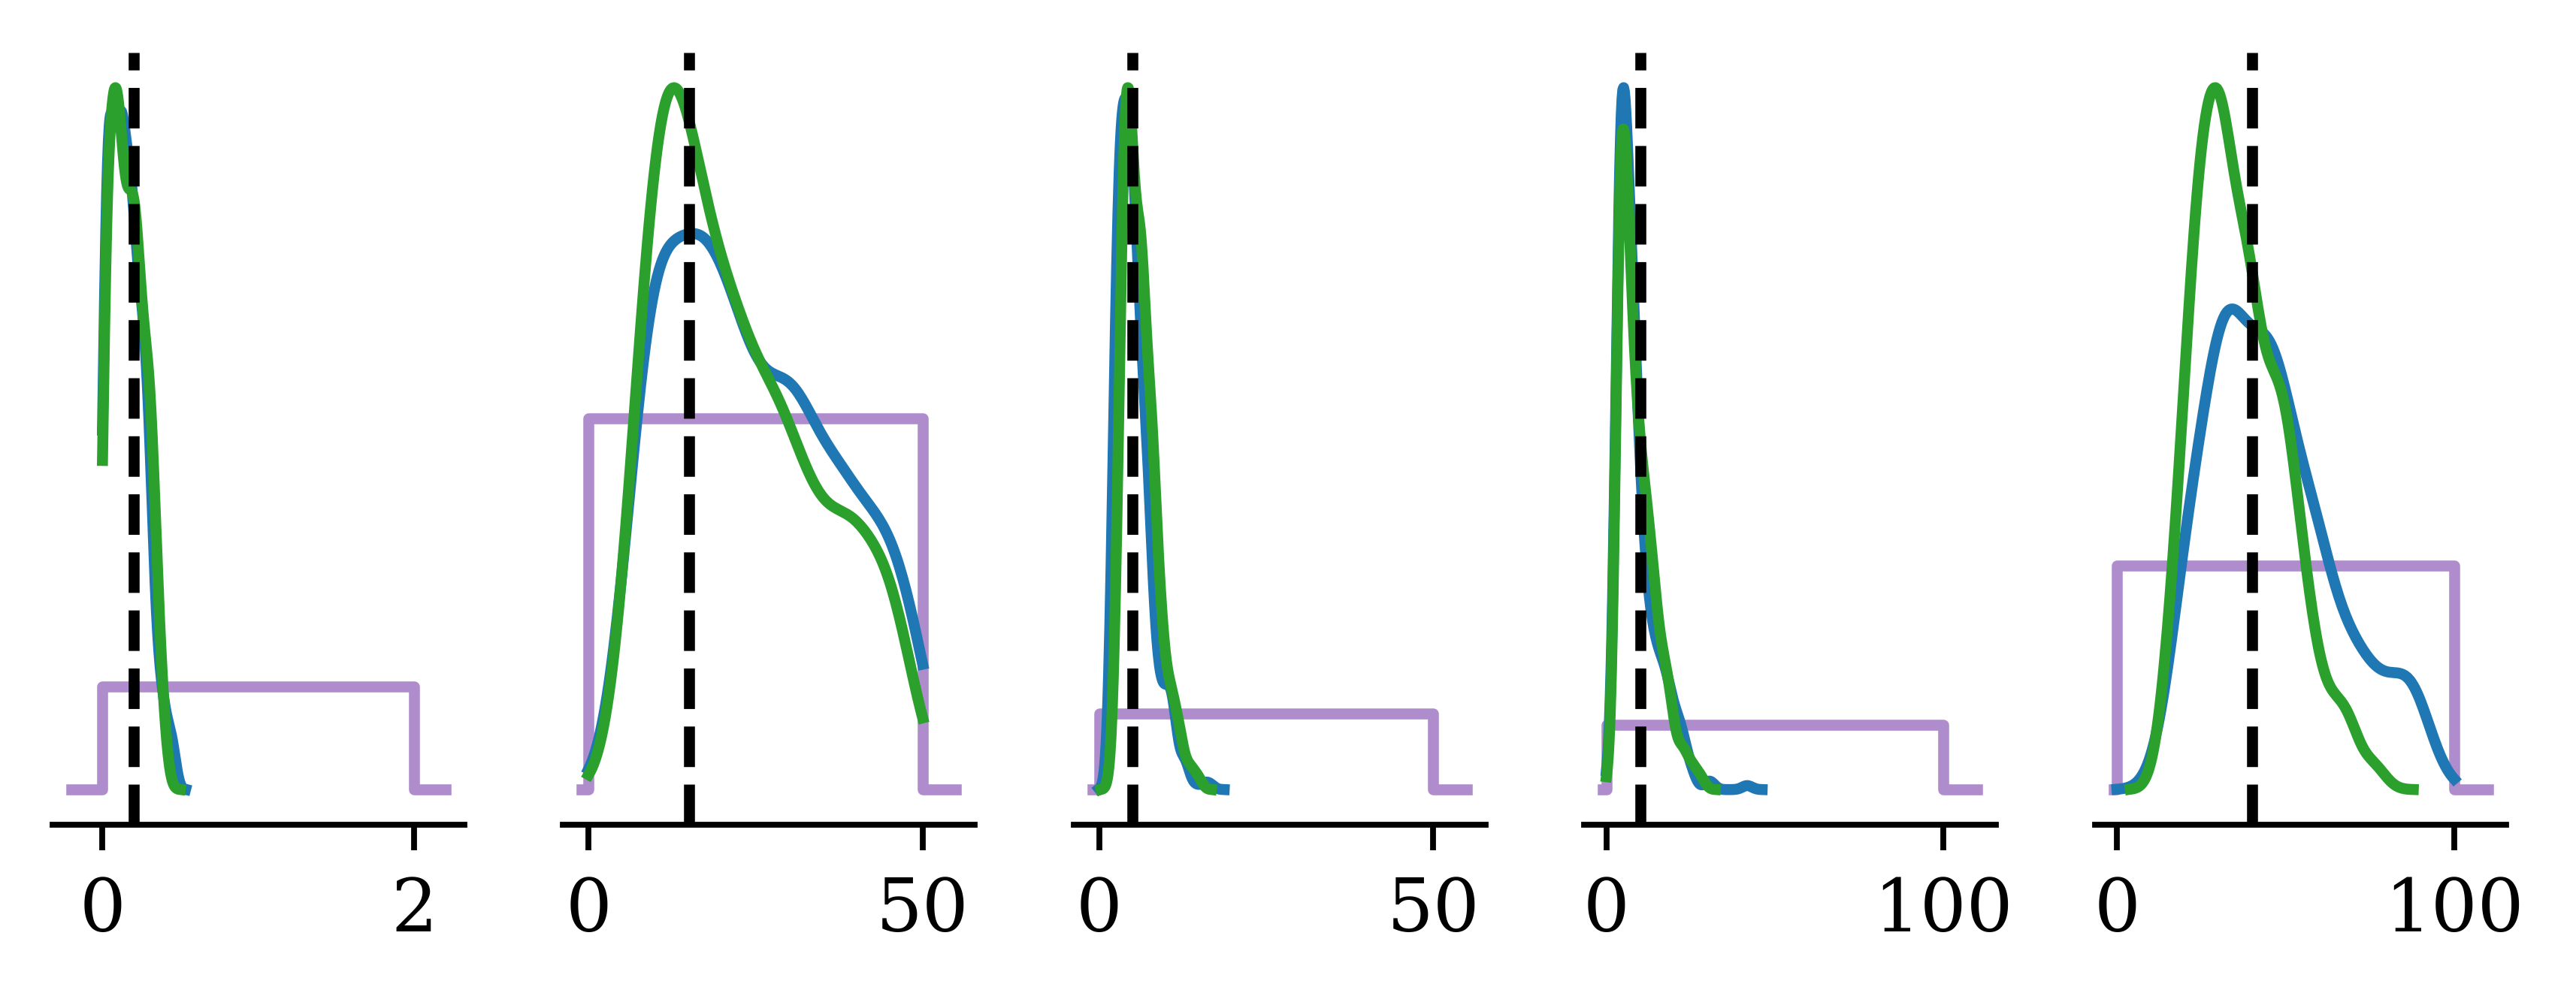

In [16]:
fig, axs = plt.subplots(1, len(params), tight_layout=True)

for l in range(len(params)):
    pLims = [prior.marginals[l].isf(1), prior.marginals[l].isf(0)]
    # axs[l].set_xlim(pLims)

    for k, ss in enumerate(sample_sizes):
        sampleData = dfABC.query("ss == @ss")
        sample = sampleData[params[l]]
        weights = sampleData["weights"]

        dataResampled, xs, ys = abc.resample_and_kde(sample, weights, clip=pLims)
        axs[l].plot(xs, ys, label="ABC")

    axs[l].axvline(θ_True[l], **trueStyle)
    #     axs[l].set_title("$" + params[l] + "$")
    axs[l].set_yticks([])

draw_prior(prior, axs)
sns.despine(left=True)
# save_cropped("../Figures/hist-bivariate-poisson-exp.pdf")

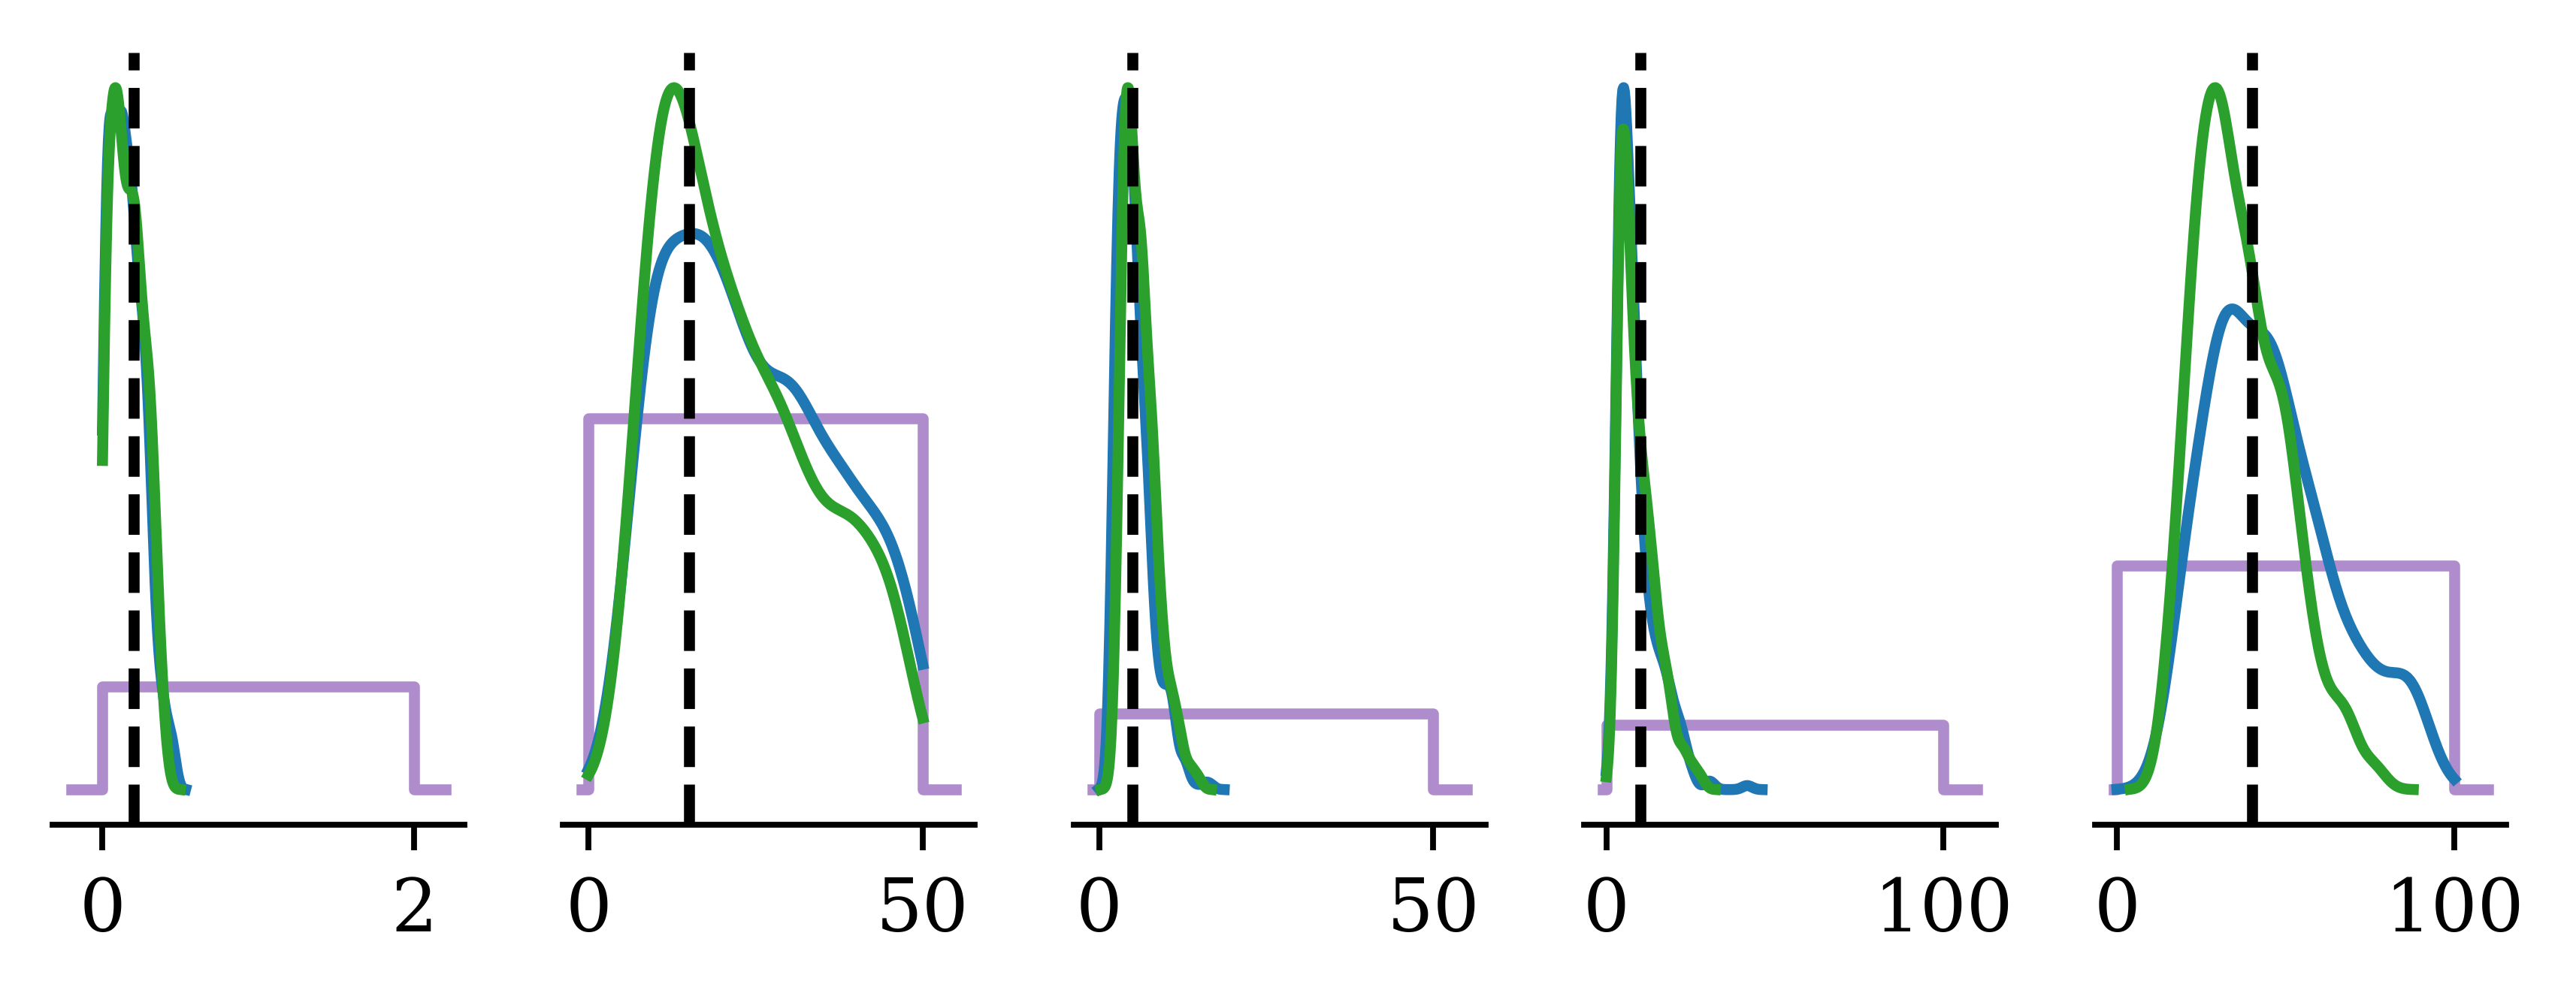

In [17]:
fig, axs = plt.subplots(1, len(params), tight_layout=True)

for l in range(len(params)):
    pLims = [prior.marginals[l].isf(1), prior.marginals[l].isf(0)]
    # axs[l].set_xlim(pLims)

    for k, ss in enumerate(sample_sizes):
        sampleData = dfABC.query("ss == @ss")
        sample = sampleData[params[l]]
        weights = sampleData["weights"]

        dataResampled, xs, ys = abc.resample_and_kde(sample, weights, clip=pLims)
        axs[l].plot(xs, ys, label="ABC")

    axs[l].axvline(θ_True[l], **trueStyle)
    #     axs[l].set_title("$" + params[l] + "$")
    axs[l].set_yticks([])

draw_prior(prior, axs)
sns.despine(left=True)
# save_cropped("../Figures/hist-bivariate-poisson-exp.pdf")

In [18]:
elapsed = toc()
print(f"Notebook time = {elapsed:.0f} secs = {elapsed/60:.2f} mins")

Notebook time = 6096 secs = 101.61 mins


In [19]:
dill.dump_session("Sim_Bivariate_Poisson_Exp.pkl")